# MSCS 634: Data Mining and Machine Learning
## Lab 6: Association Rule Mining with Apriori and FP-Growth

**Name:** Nikita Metha  
**Course:** MSCS 634: Data Mining and Machine Learning  
**Assignment:** Transaction Analysis with Frequent Itemsets and Association Rules

## Purpose

This lab uses the public [UCI Online Retail dataset](https://archive.ics.uci.edu/dataset/352/online+retail), which records products purchased on customer invoices. After cleaning the records, the analysis builds a transaction-product basket, explores product frequency and co-occurrence, mines frequent itemsets with Apriori and FP-Growth, and generates association rules.

The source workbook contains more than 500,000 invoice lines. To keep the notebook practical and make algorithm timings reproducible, it uses a seeded sample of at most 5,000 eligible UK invoices and the 25 most frequently purchased products in that sample. The same basket, support threshold, and maximum itemset size are used for both algorithms. Results therefore describe this sampled, restricted basket rather than every product in the full dataset.

## Step 1: Data Preparation and Exploration

In [1]:
# Import data, visualization, timing, and association-mining tools.
from io import BytesIO
from math import ceil
from statistics import median
from time import perf_counter
from zipfile import ZipFile

import matplotlib.pyplot as plt
import mlxtend
import pandas as pd
import requests
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth

RANDOM_STATE = 42
MAX_TRANSACTIONS = 5_000
TOP_ITEM_COUNT = 25
MIN_SUPPORT = 0.01
MIN_CONFIDENCE = 0.50
MAX_ITEMSET_LENGTH = 3
BENCHMARK_REPEATS = 5
SUPPORT_GRID = [0.005, 0.01, 0.02, 0.03, 0.05]
DATA_URL = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

sns.set_theme(style="whitegrid")
print(f"pandas: {pd.__version__} | mlxtend: {mlxtend.__version__}")

pandas: 2.3.3 | mlxtend: 0.23.4


### Load and Clean the Transactions

In [2]:
# Download and read the workbook distributed in UCI's public ZIP archive.
response = requests.get(DATA_URL, timeout=90)
response.raise_for_status()
with ZipFile(BytesIO(response.content)) as archive:
    workbook_name = next(name for name in archive.namelist() if name.endswith(".xlsx"))
    retail = pd.read_excel(archive.open(workbook_name), engine="openpyxl")

print(f"Workbook: {workbook_name}")
print(f"Raw shape: {retail.shape[0]:,} rows x {retail.shape[1]} columns")
display(retail.head())
print("\nColumn types:")
display(retail.dtypes.to_frame("dtype").T)

Workbook: Online Retail.xlsx
Raw shape: 541,909 rows x 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Column types:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
dtype,object,object,object,int64,datetime64[ns],float64,float64,object


### Dataset Structure

Each row is one product line on an invoice. An invoice (transaction) therefore spans one or more rows, and the product `Description` is the item.

| Column | Meaning |
|---|---|
| `InvoiceNo` | Invoice identifier; values starting with `C` are cancellations. This is the transaction ID. |
| `StockCode` | Product code. |
| `Description` | Product name; used as the item in each basket. |
| `Quantity` | Units purchased on the line (negative for returns). |
| `InvoiceDate` | Invoice timestamp. |
| `UnitPrice` | Price per unit in sterling. |
| `CustomerID` | Customer identifier; often missing. |
| `Country` | Customer country. |

The next cell quantifies missing values, duplicates, and value ranges in the raw data so the cleaning rules are justified by evidence.

,missing,missing_pct,unique_values
InvoiceNo,0,0.00,25900
StockCode,0,0.00,4070
Description,1454,0.27,4223
Quantity,0,0.00,722
InvoiceDate,0,0.00,23260
UnitPrice,0,0.00,1630
CustomerID,135080,24.93,4372
Country,0,0.00,38


Invoices: 25,900 | Products: 4,223 | Countries: 38
Date range: 2010-12-01 to 2011-12-09
Exact duplicate lines: 5,268 (kept; baskets only record whether a product was purchased)
Cancelled-invoice lines: 9,288
Lines with non-positive quantity: 10,624 | with non-positive price: 2,517


,Quantity,UnitPrice
count,541909.00,541909.00
mean,9.55,4.61
std,218.08,96.76
min,-80995.00,-11062.06
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,80995.00,38970.00


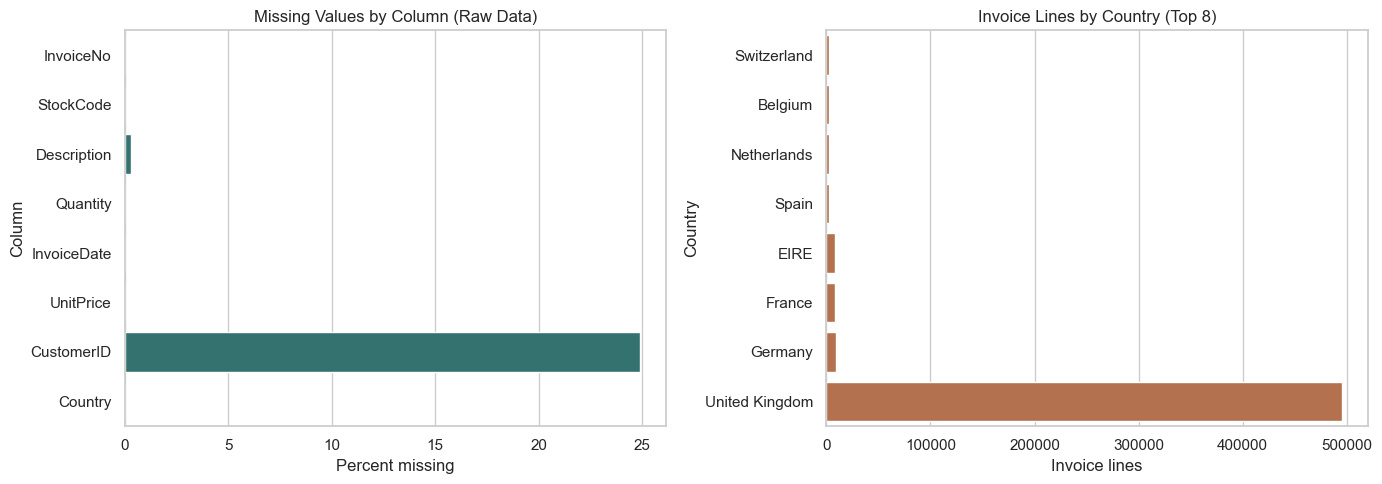

In [3]:
# Profile the raw data before cleaning: missing values, duplicates, ranges, and country mix.
raw_summary = pd.DataFrame({
    "missing": retail.isna().sum(),
    "missing_pct": (retail.isna().mean() * 100).round(2),
    "unique_values": retail.nunique(),
})
display(raw_summary)
print(f"Invoices: {retail['InvoiceNo'].nunique():,} | Products: {retail['Description'].nunique():,} | Countries: {retail['Country'].nunique()}")
print(f"Date range: {retail['InvoiceDate'].min():%Y-%m-%d} to {retail['InvoiceDate'].max():%Y-%m-%d}")
print(f"Exact duplicate lines: {retail.duplicated().sum():,} (kept; baskets only record whether a product was purchased)")
print(f"Cancelled-invoice lines: {retail['InvoiceNo'].astype(str).str.startswith('C').sum():,}")
print(f"Lines with non-positive quantity: {(retail['Quantity'] <= 0).sum():,} | with non-positive price: {(retail['UnitPrice'] <= 0).sum():,}")
display(retail[["Quantity", "UnitPrice"]].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=raw_summary["missing_pct"], y=raw_summary.index, ax=axes[0], color="#287D78")
axes[0].set(title="Missing Values by Column (Raw Data)", xlabel="Percent missing", ylabel="Column")
country_counts = retail["Country"].value_counts().head(8).sort_values()
sns.barplot(x=country_counts.values, y=country_counts.index, ax=axes[1], color="#C56B3E")
axes[1].set(title="Invoice Lines by Country (Top 8)", xlabel="Invoice lines", ylabel="Country")
plt.tight_layout()
plt.show()

,step,rows_remaining,rows_removed
0,Raw data,541909,0
1,Drop missing required fields,540455,1454
2,Remove cancelled invoices,531167,9288
3,Keep positive quantity and price,530104,1063
4,Remove postage/fee lines,527794,2310
5,Keep United Kingdom only,484040,43754


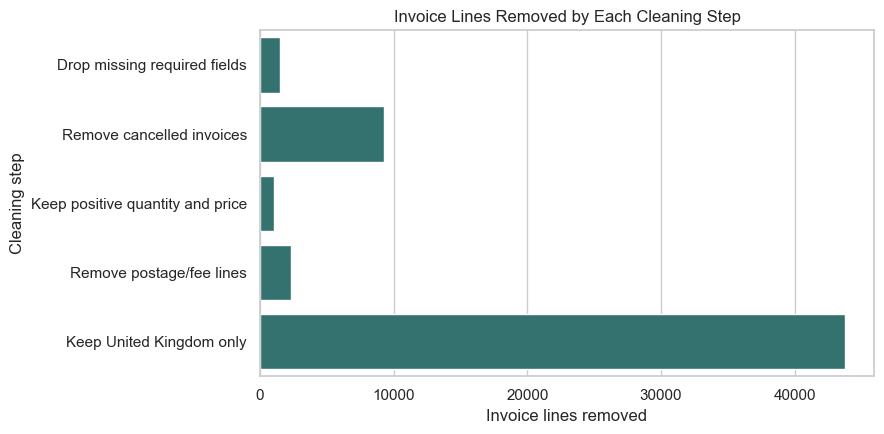

Clean UK invoice lines: 484,040
Eligible invoices: 17,903
Missing values after cleaning:
{'InvoiceNo': 0, 'StockCode': 0, 'Description': 0, 'Quantity': 0, 'InvoiceDate': 0, 'UnitPrice': 0, 'CustomerID': 130052, 'Country': 0}
Unique products after cleaning: 3,989


In [5]:
# Normalize identifiers and descriptions, then remove records that cannot represent a purchase.
retail["InvoiceNo"] = retail["InvoiceNo"].astype(str).str.strip()
retail["Description"] = retail["Description"].astype("string").str.strip()
retail["StockCode"] = retail["StockCode"].astype("string").str.strip()
non_product_descriptions = {
    "POSTAGE", "DOTCOM POSTAGE", "MANUAL", "BANK CHARGES",
    "AMAZON FEE", "CRUK COMMISSION", "CARRIAGE", "ADJUST BAD DEBT"
}

# Apply each rule in order and log the rows remaining so the effect of every step is visible.
cleaning_log = [{"step": "Raw data", "rows_remaining": len(retail)}]
retail_clean = retail.dropna(subset=["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "Country"]).copy()
cleaning_log.append({"step": "Drop missing required fields", "rows_remaining": len(retail_clean)})
retail_clean = retail_clean[~retail_clean["InvoiceNo"].str.startswith("C")]
cleaning_log.append({"step": "Remove cancelled invoices", "rows_remaining": len(retail_clean)})
retail_clean = retail_clean[retail_clean["Quantity"].gt(0) & retail_clean["UnitPrice"].gt(0)]
cleaning_log.append({"step": "Keep positive quantity and price", "rows_remaining": len(retail_clean)})
retail_clean = retail_clean[
    retail_clean["Description"].ne("")
    & ~retail_clean["Description"].str.upper().isin(non_product_descriptions)
]
cleaning_log.append({"step": "Remove postage/fee lines", "rows_remaining": len(retail_clean)})
retail_clean = retail_clean[retail_clean["Country"].eq("United Kingdom")].copy()
cleaning_log.append({"step": "Keep United Kingdom only", "rows_remaining": len(retail_clean)})

cleaning_summary = pd.DataFrame(cleaning_log)
cleaning_summary["rows_removed"] = -cleaning_summary["rows_remaining"].diff().fillna(0).astype(int)
display(cleaning_summary)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=cleaning_summary.iloc[1:], x="rows_removed", y="step", color="#287D78")
plt.title("Invoice Lines Removed by Each Cleaning Step")
plt.xlabel("Invoice lines removed")
plt.ylabel("Cleaning step")
plt.tight_layout()
plt.show()

print(f"Clean UK invoice lines: {len(retail_clean):,}")
print(f"Eligible invoices: {retail_clean['InvoiceNo'].nunique():,}")
print(f"Missing values after cleaning:\n{retail_clean.isna().sum().to_dict()}")
print(f"Unique products after cleaning: {retail_clean['Description'].nunique():,}")

The cleaning removes cancelled invoices (invoice numbers beginning with `C`), non-positive quantities and prices, missing product or invoice fields, and common postage/fee adjustment lines. The analysis focuses on United Kingdom invoices so it has one country context. It samples invoice IDs, not individual lines, so all retained product rows for each sampled invoice stay together.

In [6]:
# Select a reproducible invoice sample, then limit the basket to its most frequent products.
eligible_invoices = retail_clean["InvoiceNo"].drop_duplicates()
sample_size = min(MAX_TRANSACTIONS, len(eligible_invoices))
sampled_invoices = eligible_invoices.sample(n=sample_size, random_state=RANDOM_STATE)
sampled_lines = retail_clean[retail_clean["InvoiceNo"].isin(sampled_invoices)].copy()
top_items = sampled_lines["Description"].value_counts().head(TOP_ITEM_COUNT).index
selected_lines = sampled_lines[sampled_lines["Description"].isin(top_items)]

# Preserve invoices with none of the selected products as all-false rows so support uses the full sample.
basket = selected_lines.pivot_table(
    index="InvoiceNo", columns="Description", values="Quantity",
    aggfunc="sum", fill_value=0
)
basket = basket.reindex(index=sampled_invoices, columns=top_items, fill_value=0).gt(0)

print(f"Seeded invoice sample: {sample_size:,} invoices")
print(f"Basket shape: {basket.shape[0]:,} invoices x {basket.shape[1]} products")
print(f"Support threshold: {MIN_SUPPORT:.1%} ({ceil(MIN_SUPPORT * len(basket))} or more invoices)")
display(basket.head())

Seeded invoice sample: 5,000 invoices
Basket shape: 5,000 invoices x 25 products
Support threshold: 1.0% (50 or more invoices)


Description,WHITE HANGING HEART T-LIGHT HOLDER,JUMBO BAG RED RETROSPOT,REGENCY CAKESTAND 3 TIER,PARTY BUNTING,LUNCH BAG RED RETROSPOT,ASSORTED COLOUR BIRD ORNAMENT,LUNCH BAG BLACK SKULL.,SET OF 3 CAKE TINS PANTRY DESIGN,PAPER CHAIN KIT 50'S CHRISTMAS,NATURAL SLATE HEART CHALKBOARD,...,LUNCH BAG SPACEBOY DESIGN,WOODEN PICTURE FRAME WHITE FINISH,LUNCH BAG SUKI DESIGN,LUNCH BAG PINK POLKADOT,VICTORIAN GLASS HANGING T-LIGHT,JAM MAKING SET WITH JARS,JAM MAKING SET PRINTED,JUMBO STORAGE BAG SUKI,SPOTTY BUNTING,RECIPE BOX PANTRY YELLOW DESIGN
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
543242,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
559401,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536838,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
560644,True,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
557963,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


### Explore Item Frequencies and Co-Occurrence

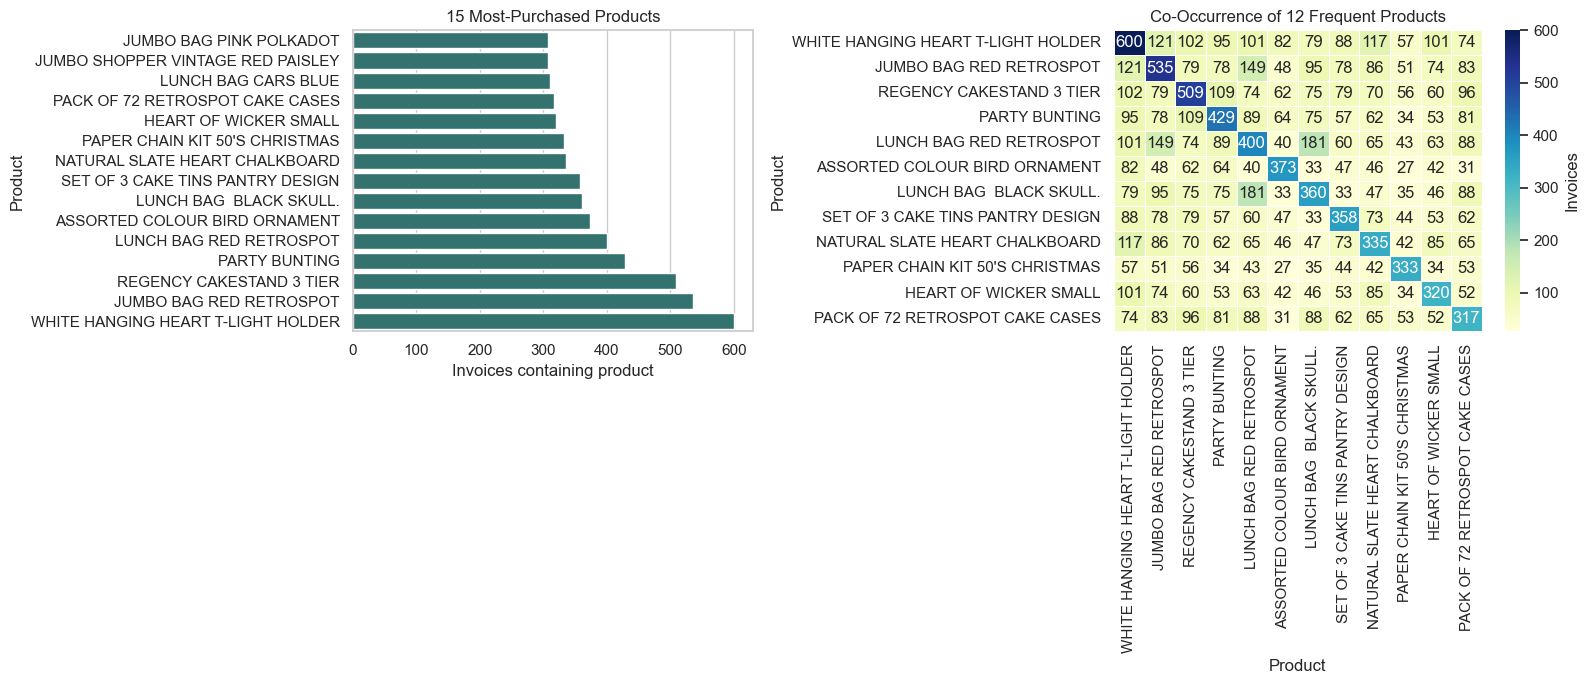

Most frequent item: WHITE HANGING HEART T-LIGHT HOLDER (600 invoices, 12.0% support)


In [7]:
item_counts = basket.sum().sort_values(ascending=False)
top_15_counts = item_counts.head(15).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1, 1.15]})
sns.barplot(x=top_15_counts.values, y=top_15_counts.index, ax=axes[0], color="#287D78")
axes[0].set(title="15 Most-Purchased Products", xlabel="Invoices containing product", ylabel="Product")

# Co-occurrence counts show how many sampled invoices contain both products.
heatmap_items = item_counts.head(12).index
heatmap_matrix = basket[heatmap_items].astype(int).T.dot(basket[heatmap_items].astype(int))
sns.heatmap(heatmap_matrix, cmap="YlGnBu", annot=True, fmt="d", linewidths=0.4, ax=axes[1], cbar_kws={"label": "Invoices"})
axes[1].set(title="Co-Occurrence of 12 Frequent Products", xlabel="Product", ylabel="Product")
plt.tight_layout()
plt.show()

print(f"Most frequent item: {item_counts.index[0]} ({item_counts.iloc[0]:,} invoices, {item_counts.iloc[0] / len(basket):.1%} support)")

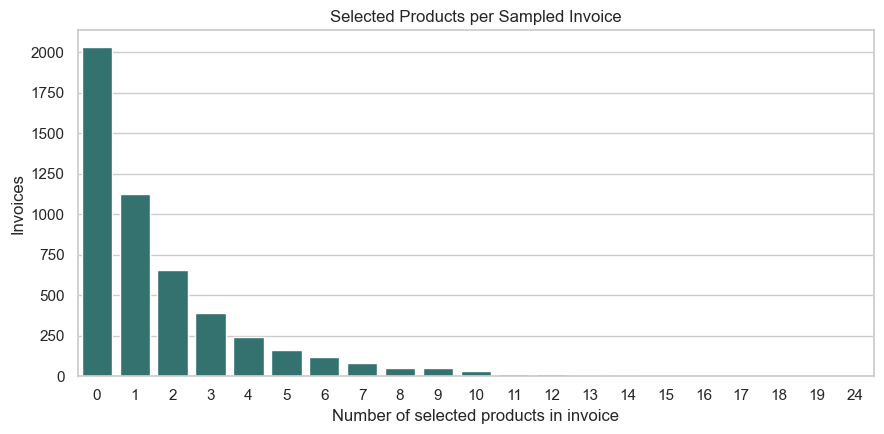

Invoices with no selected product: 2,033 (40.7%)
Invoices with 2+ selected products (able to support a multi-item itemset): 1,845 (36.9%)


In [8]:
# Show how many of the selected products each sampled invoice contains; this bounds which itemset sizes can occur.
items_per_invoice = basket.sum(axis=1)
plt.figure(figsize=(9, 4.5))
sns.countplot(x=items_per_invoice, color="#287D78")
plt.title("Selected Products per Sampled Invoice")
plt.xlabel("Number of selected products in invoice")
plt.ylabel("Invoices")
plt.tight_layout()
plt.show()

print(f"Invoices with no selected product: {(items_per_invoice == 0).sum():,} ({(items_per_invoice == 0).mean():.1%})")
print(f"Invoices with 2+ selected products (able to support a multi-item itemset): {(items_per_invoice >= 2).sum():,} ({(items_per_invoice >= 2).mean():.1%})")

## Step 2: Frequent Itemsets with Apriori

Support is the fraction of sampled invoices containing an itemset. The 1% threshold requires an itemset to occur in at least 50 of the 5,000 sampled invoices. Itemsets are capped at length three to make the comparison focused and computationally bounded.

The 1% threshold is a deliberate choice, supported by the sensitivity sweep in Step 3: at 5% every one of the 25 items is frequent but no multi-item itemset survives, so no rules can be formed; at 0.5% the number of itemsets more than triples and many rest on fewer than 50 invoices. At 1% the output is large enough to yield meaningful rules while each itemset still rests on at least 50 invoices.

Apriori runtime: 0.0226 seconds
Frequent itemsets found: 237


,support,itemsets
0,0.1200,"(WHITE HANGING HEART T-LIGHT HOLDER,)"
1,0.1070,"(JUMBO BAG RED RETROSPOT,)"
2,0.1018,"(REGENCY CAKESTAND 3 TIER,)"
3,0.0858,"(PARTY BUNTING,)"
4,0.0800,"(LUNCH BAG RED RETROSPOT,)"
5,0.0746,"(ASSORTED COLOUR BIRD ORNAMENT,)"
6,0.0720,"(LUNCH BAG BLACK SKULL.,)"
7,0.0716,"(SET OF 3 CAKE TINS PANTRY DESIGN,)"
8,0.0670,"(NATURAL SLATE HEART CHALKBOARD,)"
9,0.0666,"(PAPER CHAIN KIT 50'S CHRISTMAS,)"


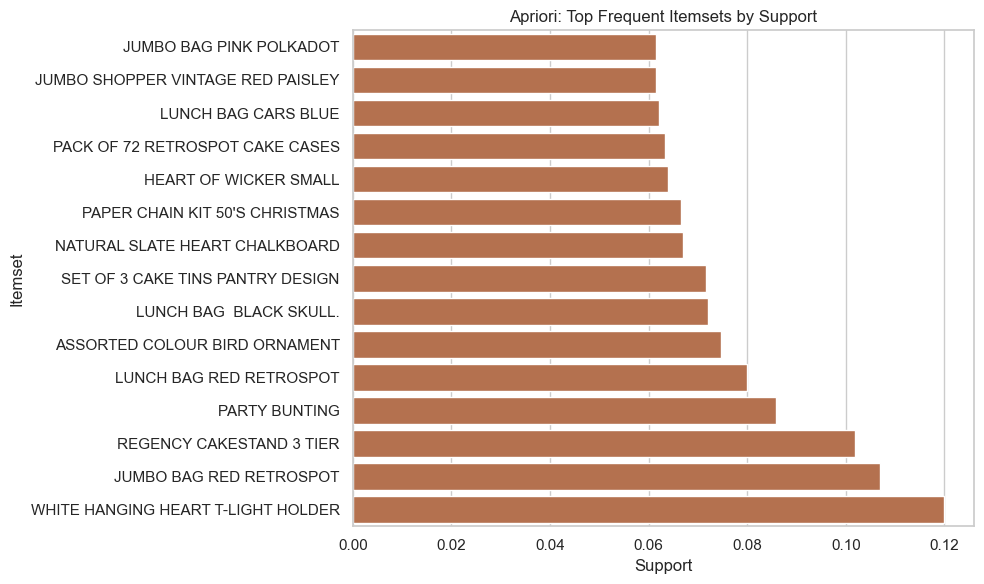

In [9]:
# Time the mining call only so the runtime comparison uses the same measured scope.
start = perf_counter()
apriori_itemsets = apriori(
    basket, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_ITEMSET_LENGTH
)
apriori_seconds = perf_counter() - start

# Sort by support so the most frequent itemsets appear first.
apriori_itemsets = apriori_itemsets.sort_values("support", ascending=False).reset_index(drop=True)

# Plot the highest-support itemsets and handle an empty result gracefully.
def show_itemsets(frame, title):
    if frame.empty:
        print(f"No itemsets met the selected support threshold for {title}.")
        return
    shown = frame.copy()
    shown["items"] = shown["itemsets"].apply(lambda values: ", ".join(sorted(values)))
    plot_data = shown.head(15).sort_values("support")
    plt.figure(figsize=(10, 6))
    sns.barplot(data=plot_data, x="support", y="items", color="#C56B3E")
    plt.title(title)
    plt.xlabel("Support")
    plt.ylabel("Itemset")
    plt.tight_layout()
    plt.show()

print(f"Apriori runtime: {apriori_seconds:.4f} seconds")
print(f"Frequent itemsets found: {len(apriori_itemsets):,}")
# Show the top 20 itemsets with readable, consistently ordered product names.
display(apriori_itemsets.assign(itemsets=apriori_itemsets["itemsets"].apply(lambda values: tuple(sorted(values)))).head(20))
show_itemsets(apriori_itemsets, "Apriori: Top Frequent Itemsets by Support")

## Step 3: Frequent Itemsets with FP-Growth

FP-Growth uses a compressed prefix tree to avoid Apriori's repeated candidate generation. It receives the identical Boolean basket, support threshold, and maximum itemset length. Its frequent itemsets should match Apriori's; the measured runtimes can differ with dataset size, item frequency, hardware, and library implementation.

FP-Growth runtime: 1.0570 seconds
Frequent itemsets found: 237


,support,itemsets
0,0.1200,"(WHITE HANGING HEART T-LIGHT HOLDER,)"
1,0.1070,"(JUMBO BAG RED RETROSPOT,)"
2,0.1018,"(REGENCY CAKESTAND 3 TIER,)"
3,0.0858,"(PARTY BUNTING,)"
4,0.0800,"(LUNCH BAG RED RETROSPOT,)"
5,0.0746,"(ASSORTED COLOUR BIRD ORNAMENT,)"
6,0.0720,"(LUNCH BAG BLACK SKULL.,)"
7,0.0716,"(SET OF 3 CAKE TINS PANTRY DESIGN,)"
8,0.0670,"(NATURAL SLATE HEART CHALKBOARD,)"
9,0.0666,"(PAPER CHAIN KIT 50'S CHRISTMAS,)"


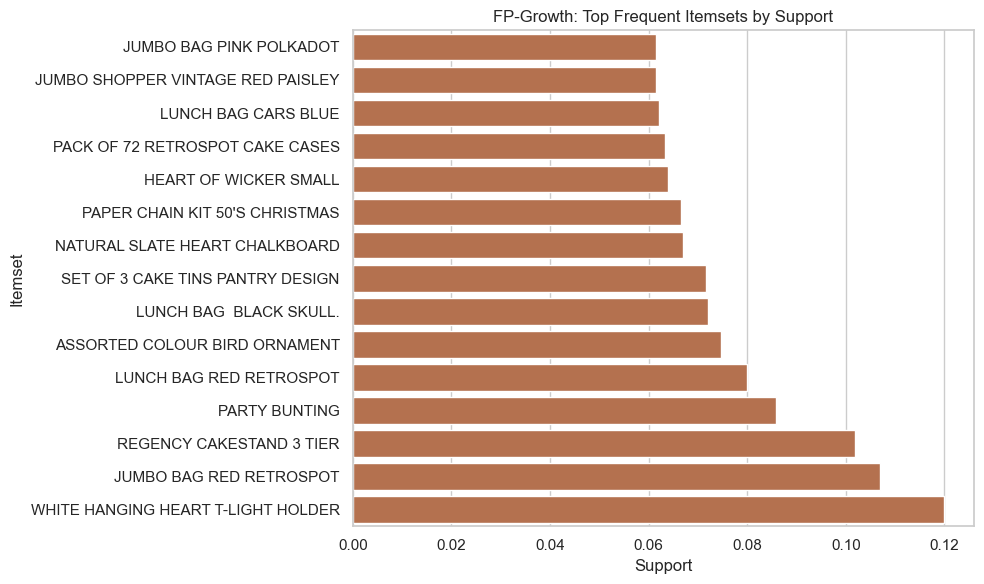

In [10]:
# Use the same basket and support settings as Apriori for a fair output comparison.
# FP-Growth organizes frequent patterns without explicit candidate generation.
start = perf_counter()
fpgrowth_itemsets = fpgrowth(
    basket, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_ITEMSET_LENGTH
)
fpgrowth_seconds = perf_counter() - start

# Sort by support to make the printed results easy to compare with Apriori.
fpgrowth_itemsets = fpgrowth_itemsets.sort_values("support", ascending=False).reset_index(drop=True)

print(f"FP-Growth runtime: {fpgrowth_seconds:.4f} seconds")
print(f"Frequent itemsets found: {len(fpgrowth_itemsets):,}")
display(fpgrowth_itemsets.assign(itemsets=fpgrowth_itemsets["itemsets"].apply(lambda values: tuple(sorted(values)))).head(20))
show_itemsets(fpgrowth_itemsets, "FP-Growth: Top Frequent Itemsets by Support")

In [11]:
# Compare sets of itemsets, not their row order, because the algorithms may return different ordering.
apriori_set = set(apriori_itemsets["itemsets"].map(frozenset))
fpgrowth_set = set(fpgrowth_itemsets["itemsets"].map(frozenset))
itemsets_match = apriori_set == fpgrowth_set

# Summarize runtime and output size side by side.
comparison = pd.DataFrame([
    {"algorithm": "Apriori", "runtime_seconds": apriori_seconds, "itemset_count": len(apriori_set)},
    {"algorithm": "FP-Growth", "runtime_seconds": fpgrowth_seconds, "itemset_count": len(fpgrowth_set)},
])
display(comparison.round(4))
print(f"Itemset results match: {itemsets_match}")
print(f"Apriori-only itemsets: {len(apriori_set - fpgrowth_set)} | FP-Growth-only itemsets: {len(fpgrowth_set - apriori_set)}")
assert itemsets_match, "Apriori and FP-Growth should find the same itemsets with the same settings."

,algorithm,runtime_seconds,itemset_count
0,Apriori,0.0226,237
1,FP-Growth,1.0570,237


Itemset results match: True
Apriori-only itemsets: 0 | FP-Growth-only itemsets: 0


median_runtime_seconds           itemset_count          
algorithm                  Apriori FP-Growth       Apriori FP-Growth
min_support                                                         
0.005                       0.0302    3.8904         825.0     825.0
0.010                       0.0179    1.0558         237.0     237.0
0.020                       0.0067    0.1932          61.0      61.0
0.030                       0.0034    0.0616          34.0      34.0
0.050                       0.0032    0.0167          25.0      25.0

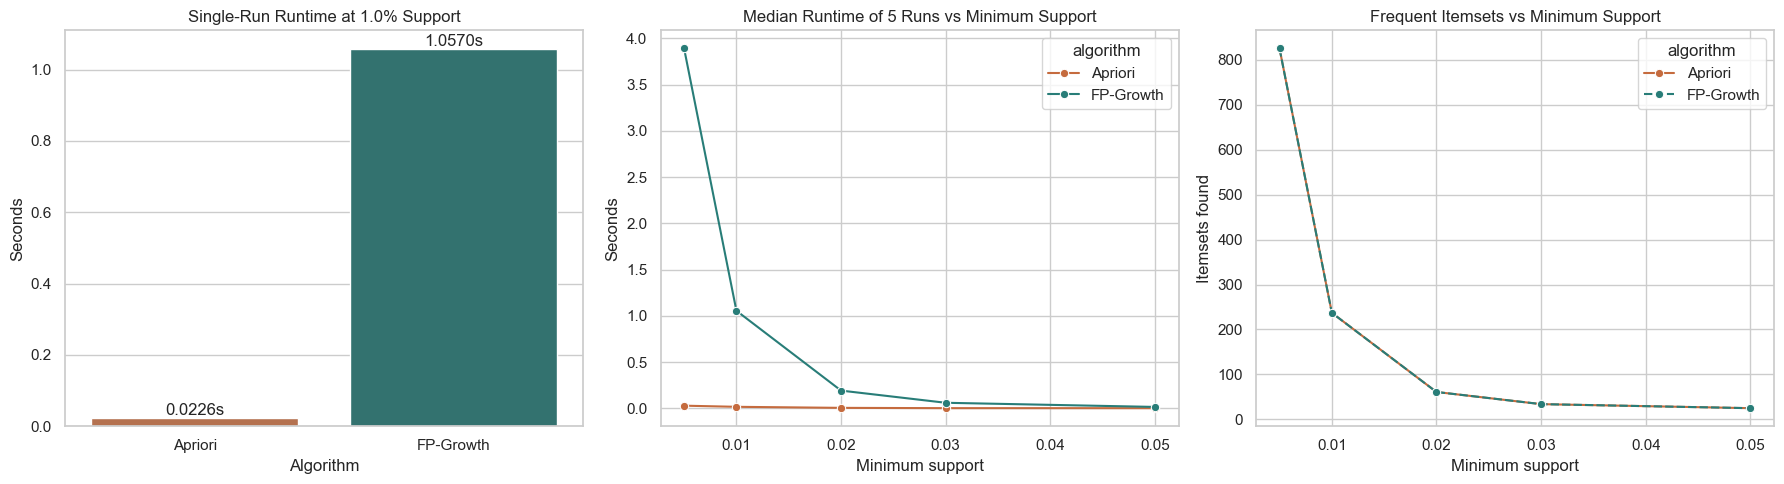

In [12]:
# Repeat each run and keep the median so one noisy timing does not drive the comparison.
def benchmark(miner, min_support):
    runtimes = []
    for _ in range(BENCHMARK_REPEATS):
        start = perf_counter()
        result = miner(basket, min_support=min_support, use_colnames=True, max_len=MAX_ITEMSET_LENGTH)
        runtimes.append(perf_counter() - start)
    return median(runtimes), len(result)

benchmark_rows = []
for support in SUPPORT_GRID:
    for name, miner in [("Apriori", apriori), ("FP-Growth", fpgrowth)]:
        seconds, count = benchmark(miner, support)
        benchmark_rows.append({"min_support": support, "algorithm": name, "median_runtime_seconds": seconds, "itemset_count": count})
benchmark_results = pd.DataFrame(benchmark_rows)
display(benchmark_results.pivot(index="min_support", columns="algorithm", values=["median_runtime_seconds", "itemset_count"]).round(4))

# Left: single run at the chosen threshold; middle: median runtime vs support; right: itemset count vs support.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=comparison, x="algorithm", y="runtime_seconds", hue="algorithm", ax=axes[0], palette=["#C56B3E", "#287D78"], legend=False)
axes[0].set(title=f"Single-Run Runtime at {MIN_SUPPORT:.1%} Support", xlabel="Algorithm", ylabel="Seconds")
for bar in axes[0].patches:
    axes[0].annotate(f"{bar.get_height():.4f}s", (bar.get_x() + bar.get_width() / 2, bar.get_height()), ha="center", va="bottom")
sns.lineplot(data=benchmark_results, x="min_support", y="median_runtime_seconds", hue="algorithm", marker="o", ax=axes[1], palette=["#C56B3E", "#287D78"])
axes[1].set(title=f"Median Runtime of {BENCHMARK_REPEATS} Runs vs Minimum Support", xlabel="Minimum support", ylabel="Seconds")
sns.lineplot(data=benchmark_results, x="min_support", y="itemset_count", hue="algorithm", style="algorithm", marker="o", ax=axes[2], palette=["#C56B3E", "#287D78"])
axes[2].set(title="Frequent Itemsets vs Minimum Support", xlabel="Minimum support", ylabel="Itemsets found")
plt.tight_layout()
plt.show()

# Both algorithms must find identical itemset counts at every threshold.
counts_by_support = benchmark_results.pivot(index="min_support", columns="algorithm", values="itemset_count")
assert (counts_by_support["Apriori"] == counts_by_support["FP-Growth"]).all(), "Itemset counts differ at some support threshold."

## Step 4: Generate and Analyze Association Rules

Confidence measures how often the consequent appears when the antecedent appears. Lift compares that confidence with the consequent's overall support: a lift above 1 indicates a positive association in this sample, not proof of causation. Rules below use a 50% minimum confidence.

In [13]:
# Build directed rules from frequent itemsets; return an empty result if no pair qualifies.
def make_rules(itemsets):
    if itemsets.empty or itemsets["itemsets"].map(len).max() < 2:
        return pd.DataFrame(columns=["antecedents", "consequents", "support", "confidence", "lift"])
    return association_rules(itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE)

# Apply the same confidence threshold to itemsets from both algorithms.
apriori_rules = make_rules(apriori_itemsets)
fpgrowth_rules = make_rules(fpgrowth_itemsets)

# Convert item collections to readable strings for the output table.
def format_rules(frame):
    formatted = frame.copy()
    for column in ["antecedents", "consequents"]:
        if column in formatted:
            formatted[column] = formatted[column].apply(lambda values: ", ".join(sorted(values)))
    return formatted

print(f"Apriori rules: {len(apriori_rules):,} | FP-Growth rules: {len(fpgrowth_rules):,}")
# Rank by lift, then confidence, to surface strong rules first.
display(format_rules(apriori_rules).sort_values(["lift", "confidence"], ascending=False).head(15))

Apriori rules: 95 | FP-Growth rules: 95


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
55,"JUMBO BAG PINK POLKADOT, JUMBO SHOPPER VINTAGE...",JUMBO STORAGE BAG SUKI,0.0222,0.0572,0.0150,0.675676,11.812512,1.0,0.013730,2.906967,0.936126,0.232919,0.655999,0.468957
75,"JAM MAKING SET PRINTED, RECIPE BOX PANTRY YELL...",JAM MAKING SET WITH JARS,0.0172,0.0574,0.0112,0.651163,11.344299,1.0,0.010213,2.702120,0.927808,0.176656,0.629920,0.423142
40,"LUNCH BAG CARS BLUE, LUNCH BAG SPACEBOY DESIGN",LUNCH BAG SUKI DESIGN,0.0258,0.0586,0.0166,0.643411,10.979707,1.0,0.015088,2.640013,0.932994,0.244838,0.621214,0.463344
84,"JUMBO BAG RED RETROSPOT, LUNCH BAG SUKI DESIGN",JUMBO STORAGE BAG SUKI,0.0170,0.0572,0.0106,0.623529,10.900864,1.0,0.009628,2.504313,0.923972,0.166667,0.600689,0.404422
76,"JAM MAKING SET WITH JARS, RECIPE BOX PANTRY YE...",JAM MAKING SET PRINTED,0.0180,0.0572,0.0112,0.622222,10.878011,1.0,0.010170,2.495647,0.924716,0.175000,0.599302,0.409013
92,"LUNCH BAG CARS BLUE, PACK OF 72 RETROSPOT CAKE...",LUNCH BAG BLACK SKULL.,0.0132,0.0720,0.0102,0.772727,10.732323,1.0,0.009250,4.083200,0.918954,0.136000,0.755094,0.457197
86,"JAM MAKING SET PRINTED, JUMBO BAG RED RETROSPOT",JAM MAKING SET WITH JARS,0.0172,0.0574,0.0104,0.604651,10.533992,1.0,0.009413,2.384224,0.920909,0.161994,0.580576,0.392918
20,"LUNCH BAG BLACK SKULL., LUNCH BAG CARS BLUE",LUNCH BAG PINK POLKADOT,0.0320,0.0580,0.0194,0.606250,10.452586,1.0,0.017544,2.392381,0.934225,0.274788,0.582006,0.470366
87,"JAM MAKING SET WITH JARS, JUMBO BAG RED RETROSPOT",JAM MAKING SET PRINTED,0.0176,0.0572,0.0104,0.590909,10.330579,1.0,0.009393,2.304622,0.919381,0.161491,0.566089,0.386364
74,"JAM MAKING SET WITH JARS, SET OF 3 CAKE TINS P...",RECIPE BOX PANTRY YELLOW DESIGN,0.0194,0.0560,0.0112,0.577320,10.309278,1.0,0.010114,2.233366,0.920865,0.174455,0.552245,0.388660


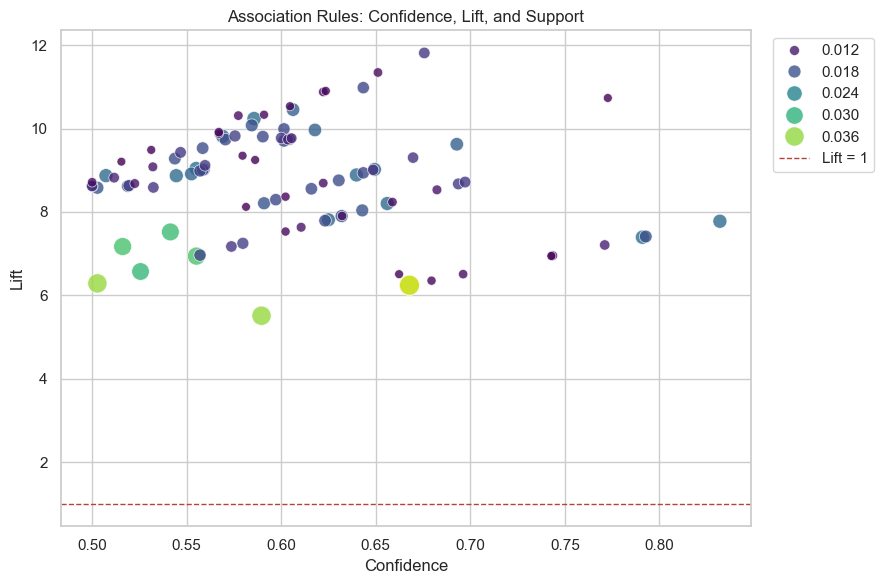

Highest-lift rule: If a basket contains [JUMBO BAG PINK POLKADOT, JUMBO SHOPPER VINTAGE RED PAISLEY], it also contains [JUMBO STORAGE BAG SUKI] with 67.6% confidence.
Support = 1.500%; lift = 11.813. Treat this as an association in the sample, not a causal claim.


In [14]:
# Skip the plot and interpretation cleanly when no rule meets the confidence threshold.
if apriori_rules.empty:
    print("No rules met the confidence threshold. Lower MIN_CONFIDENCE or MIN_SUPPORT and rerun the mining cells.")
else:
    plt.figure(figsize=(9, 6))
    # Encode support with both color and marker size to show how common each rule is.
    sns.scatterplot(
        data=apriori_rules, x="confidence", y="lift", hue="support", size="support",
        palette="viridis", sizes=(40, 220), alpha=0.8
    )
    plt.axhline(1, color="#B24438", linestyle="--", linewidth=1, label="Lift = 1")
    plt.title("Association Rules: Confidence, Lift, and Support")
    plt.xlabel("Confidence")
    plt.ylabel("Lift")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    # Report the highest-lift rule along with confidence and support for interpretation.
    best_rule = apriori_rules.sort_values(["lift", "confidence"], ascending=False).iloc[0]
    antecedent = ", ".join(sorted(best_rule["antecedents"]))
    consequent = ", ".join(sorted(best_rule["consequents"]))
    print(f"Highest-lift rule: If a basket contains [{antecedent}], it also contains [{consequent}] with {best_rule['confidence']:.1%} confidence.")
    print(f"Support = {best_rule['support']:.3%}; lift = {best_rule['lift']:.3f}. Treat this as an association in the sample, not a causal claim.")

Apriori and FP-Growth rules match: True


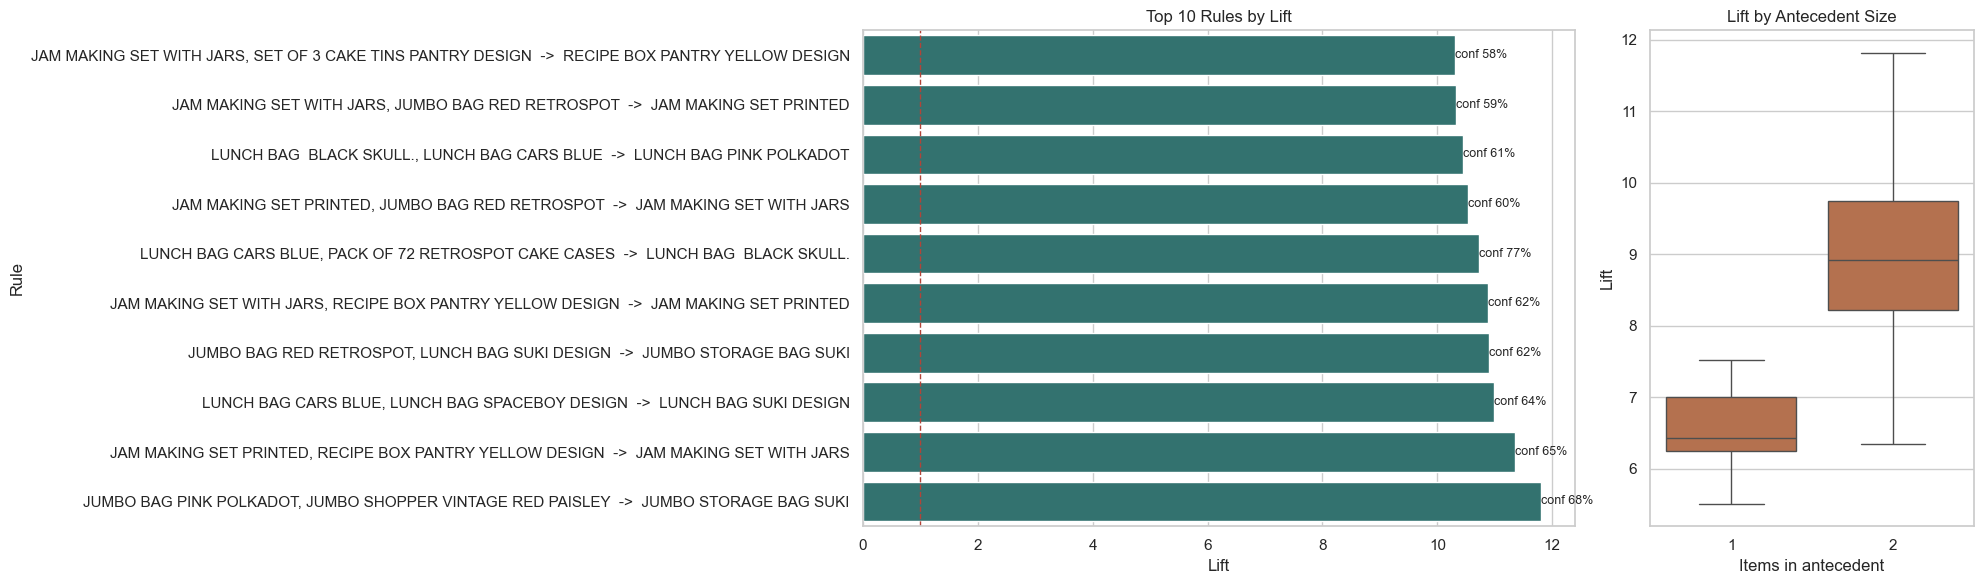

[JUMBO BAG PINK POLKADOT, JUMBO SHOPPER VINTAGE RED PAISLEY] -> [JUMBO STORAGE BAG SUKI]: 75 invoices, confidence 67.6%, lift 11.81
[JAM MAKING SET PRINTED, RECIPE BOX PANTRY YELLOW DESIGN] -> [JAM MAKING SET WITH JARS]: 56 invoices, confidence 65.1%, lift 11.34
[LUNCH BAG CARS BLUE, LUNCH BAG SPACEBOY DESIGN] -> [LUNCH BAG SUKI DESIGN]: 83 invoices, confidence 64.3%, lift 10.98

Rules with lift > 1: 95 of 95


In [15]:
# Confirm both algorithms yield the same rules, not just the same number of rules.
def rule_keys(frame):
    return set(zip(frame["antecedents"].map(frozenset), frame["consequents"].map(frozenset)))

rules_match = rule_keys(apriori_rules) == rule_keys(fpgrowth_rules)
print(f"Apriori and FP-Growth rules match: {rules_match}")
assert rules_match, "Apriori and FP-Growth should produce the same rules."

if not apriori_rules.empty:
    rules_view = format_rules(apriori_rules)
    rules_view["rule"] = rules_view["antecedents"] + "  ->  " + rules_view["consequents"]
    rules_view["antecedent_size"] = apriori_rules["antecedents"].map(len)
    top_rules = rules_view.sort_values(["lift", "confidence"], ascending=False).head(10).iloc[::-1]

    fig, axes = plt.subplots(1, 2, figsize=(20, 6), gridspec_kw={"width_ratios": [2.2, 1]})
    sns.barplot(data=top_rules, x="lift", y="rule", color="#287D78", ax=axes[0])
    axes[0].axvline(1, color="#B24438", linestyle="--", linewidth=1)
    axes[0].set(title="Top 10 Rules by Lift", xlabel="Lift", ylabel="Rule")
    for patch, confidence in zip(axes[0].patches, top_rules["confidence"]):
        axes[0].annotate(f"conf {confidence:.0%}", (patch.get_width(), patch.get_y() + patch.get_height() / 2), va="center", ha="left", fontsize=9)
    sns.boxplot(data=rules_view, x="antecedent_size", y="lift", color="#C56B3E", ax=axes[1])
    axes[1].set(title="Lift by Antecedent Size", xlabel="Items in antecedent", ylabel="Lift")
    plt.tight_layout()
    plt.show()

    # Translate the three strongest rules into plain language with their invoice counts.
    for _, rule in apriori_rules.sort_values(["lift", "confidence"], ascending=False).head(3).iterrows():
        invoices = round(rule["support"] * len(basket))
        print(f"[{', '.join(sorted(rule['antecedents']))}] -> [{', '.join(sorted(rule['consequents']))}]: "
              f"{invoices} invoices, confidence {rule['confidence']:.1%}, lift {rule['lift']:.2f}")
    print(f"\nRules with lift > 1: {(apriori_rules['lift'] > 1).sum():,} of {len(apriori_rules):,}")

### Interpreting the Rules

- **Product families drive the strongest rules.** The top rules link variants of the same product line: `LUNCH BAG` designs (Cars Blue, Spaceboy, Suki, Black Skull, Pink Polkadot), the two `JAM MAKING SET` variants, and the `JUMBO` bag variants. Customers appear to buy several designs of one product type together, which suggests bundle or cross-sell opportunities within a family.
- **Every rule has lift above 1.** Lift ranges from roughly 5.5 to 11.8, so each rule's consequent is several times more likely when the antecedent is present than its overall frequency implies. These are positive associations, not causal effects.
- **Larger antecedents give higher lift.** Two-item antecedents have a higher median lift than one-item antecedents (right panel above). Combining two products narrows the basket to a more specific shopper, so the consequent is more predictable.
- **Confidence and lift answer different questions.** The highest-confidence rules are not necessarily the highest-lift ones, so the confidence-versus-lift scatter and the top-lift bar chart are read together. The support legend shows that the highest-lift rules rest on about 1% of invoices (50 to 85 invoices), so they are strong but narrow patterns.
- **Rules are limited by the 25-product basket.** Associations among rarer products are not captured.

## Step 5: Comparative Analysis and Challenges

In [16]:
# Summarize the repeated-run benchmark at the chosen support threshold, then the full support sweep.
selected = benchmark_results[benchmark_results["min_support"].eq(MIN_SUPPORT)].set_index("algorithm")["median_runtime_seconds"]
faster_algorithm = selected.idxmin()
speed_difference = selected.max() / max(selected.min(), 1e-12)
sweep = benchmark_results.pivot(index="min_support", columns="algorithm", values="median_runtime_seconds")
fpgrowth_wins = int((sweep["FP-Growth"] < sweep["Apriori"]).sum())

print(f"Single run at {MIN_SUPPORT:.1%}: Apriori {apriori_seconds:.4f}s, FP-Growth {fpgrowth_seconds:.4f}s.")
print(f"Median of {BENCHMARK_REPEATS} runs at {MIN_SUPPORT:.1%}: {faster_algorithm} was faster ({speed_difference:.2f}x).")
print(f"FP-Growth had the lower median runtime at {fpgrowth_wins} of {len(sweep)} support thresholds tested.")
print(f"Both algorithms returned {len(apriori_set):,} matching frequent itemsets and {len(apriori_rules):,} matching rules: {itemsets_match and rules_match}.")
print("Apriori generates and tests candidate itemsets; its work can grow quickly as the item vocabulary expands.")
print("FP-Growth compresses transactions into a prefix tree and avoids explicit candidate generation, which can help on larger or denser baskets.")
print("This small, restricted basket may favor either implementation; these timings are not a universal benchmark.")

Single run at 1.0%: Apriori 0.0226s, FP-Growth 1.0570s.
Median of 5 runs at 1.0%: Apriori was faster (58.86x).
FP-Growth had the lower median runtime at 0 of 5 support thresholds tested.
Both algorithms returned 237 matching frequent itemsets and 95 matching rules: True.
Apriori generates and tests candidate itemsets; its work can grow quickly as the item vocabulary expands.
FP-Growth compresses transactions into a prefix tree and avoids explicit candidate generation, which can help on larger or denser baskets.
This small, restricted basket may favor either implementation; these timings are not a universal benchmark.


### Comparative Results and Efficiency

Both algorithms received the same Boolean basket of 5,000 sampled invoices and 25 products, with a maximum itemset length of three. At every support threshold tested (0.5% to 5%) they returned the same number of itemsets, and at 1% the itemsets and the 50% confidence rules are identical, so the two algorithms produce equivalent patterns. They differ only in how they get there.

Apriori builds and tests candidate itemsets level by level. This is straightforward and efficient when the item vocabulary and maximum itemset length are small, as they are here. As the number of distinct items grows, the number of candidate combinations can increase rapidly. FP-Growth scans the data to build a compressed FP-tree and mines conditional pattern bases, avoiding explicit candidate generation. That design is expected to pay off on larger or denser baskets, especially when many items share transaction prefixes.

In the repeated-run benchmark, Apriori had the lower median runtime at every support threshold, and the gap widened as support dropped and more itemsets had to be mined: FP-Growth took about 59 times longer at 1% support and about 129 times longer at 0.5% (see the Step 3 table and charts). FP-Growth's advantage is theoretical and mostly appears when candidate generation becomes costly. With only 25 products and itemsets of at most three items, Apriori's candidate search stays small, and the `mlxtend` FP-Growth implementation spends its time building and recursively mining trees in Python. This result does not show that Apriori is generally faster; it applies to this small, restricted basket and this library. Timings still vary with system load and software versions, which is why the benchmark reports the median of five runs.

### Challenges and Decisions

- The full workbook is large, so I used a seeded sample of 5,000 UK invoices and the 25 most frequent products to keep mining practical. This limits discovery of rare associations; about 41% of sampled invoices contain none of the selected products.
- I retained every sampled invoice in the Boolean basket, including invoices with none of the selected products. This preserves the support denominator; at 1% support, an itemset must occur in at least 50 sampled invoices.
- Many source rows have no customer ID (about 25% of the raw data), but invoice number and product description are sufficient to form transactions and items, so customer ID was not required.
- A single timing was unreliable, so I used the median of five runs across five support thresholds, with the same basket and thresholds for both algorithms. The speed difference is specific to this basket and library, not a universal result.
- Rule-level equality, not just rule counts, is asserted between the two algorithms.
- The strongest rule has 1.50% support (75 invoices), 67.57% confidence, and lift 11.81. It indicates an association in this sample, not causation.